# More Than a Hack 2027 — team possession pipeline (one notebook, step by step)

**Goal:** one label (`H` / `A` / `D` / `X`) for every one of the 199,319 frames of the tactical video. Ranking metric: **spellF1** (possessions matched by temporal IoU), tie-break **macroF1**.

**How this notebook is organised.** Each step produces a variable you can inspect before moving on. Run top to bottom the first time; afterwards you can re-run from any step.

| # | Step | Produces |
|---|---|---|
| 0 | Setup, config, data mode | `CFG`, `MATCH`, `SYNTHETIC` |
| 1 | Load tracking, teams, Smart Tagging, public ground truth | `P`, `B`, `slot_team`, `ST`, `GT_CODES` |
| 2 | Sanity checks and EDA | ball visibility, gaps, player counts |
| 3 | **Alignment check**: reproduce the published baseline | must match the numbers in `EVALUATION.md` |
| 4 | Clean the ball signal | `ball`, `ball_state`, `ball_speed` |
| 5 | Per-frame evidence (who controls the ball, is it dead?) | `FEATS` |
| 6 | Decode with a sticky 3-state HMM (Viterbi) | `labels` |
| 7 | Score, validate, inspect | scorer output, plots |
| 8 | Parameter sanity sweep | possession counts vs. switching cost |
| 9 | Export + reproducibility | `<team>.csv`, config JSON |

**Two rules that shape how we work**
1. **Data stays local.** The competition terms forbid uploading the match data (or extracts) to any hosted LLM. Run this notebook yourself and only share code, error messages and aggregate scores if you ask for help (check with the organisers whether aggregate numbers are acceptable).
2. **Never choose parameters by the public 5-minute score.** It has 17 possessions and picked the *wrong* smoothing window for the official baselines. Use it to check the pipeline is *correct*; choose parameters by structure (possession counts and durations) and by reasoning.

**Dry-run mode.** If the gated data is not found (or `FORCE_SYNTHETIC = True`), the notebook generates a small *synthetic* match in the exact file formats of the real bundle, so you can test every cell today. Synthetic scores mean nothing about football; they only prove the code runs.

## Step 0 — Setup

In [1]:
import os, sys, json, time, hashlib, warnings, copy
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the repository root (the folder that contains games.py), wherever the notebook was opened.
ROOT = Path.cwd().resolve()
while not (ROOT / "games.py").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("games.py not found - open this notebook inside the challenge repository.")
    ROOT = ROOT.parent
for p in (ROOT, ROOT / "evaluation", ROOT / "starter"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import games                      # per-game constants, asset paths, half boundaries
import possession_metrics as pm   # the official scorer (the file is the specification)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100
print("repo root:", ROOT)
print("numpy", np.__version__, "| pandas", pd.__version__)

repo root: /Users/patrickkingori/Downloads/more-than-a-hack-2027-main
numpy 2.4.6 | pandas 3.0.3


### Configuration — every tunable number lives here

The defaults are **starting points, not tuned values** (they were only exercised on synthetic data). Units are in the comments. Changing a *feature* parameter (ball cleaning, `sigma_m`, `static_*`) means re-running Steps 4–5; changing a *decoding* parameter (weights, costs, minimum durations) only needs Step 6 onward.

In [2]:
TEAM_NAME = "my_team"        # -> evaluation/results/<TEAM_NAME>.csv  (the form wants <team_name>.csv / .pdf)
FORCE_SYNTHETIC = False      # True = ignore the real data and run the dry-run mini match

CFG = dict(
    # ---- Step 4: ball cleaning (feature parameters)
    max_gap_s=0.6,            # interpolate ball gaps up to this long (seconds)
    max_ball_speed=45.0,      # m/s; isolated jumps faster than this are tracking glitches
    smooth_frames=3,          # box-filter width for ball position (frames); 1 = off

    # ---- Step 5: evidence (feature parameters)
    sigma_m=3.0,              # metres; width of a player's "control" kernel around the ball
    evidence_clip=4.0,        # cap on |log control ratio|
    min_control=0.02,         # below this total control mass the ball is "loose": no team evidence
    pitch_margin_m=0.5,       # ball this far outside the pitch rectangle counts as out of play
    static_speed=0.8,         # m/s; ball slower than this ...
    static_window_s=1.0,      # ... for this whole window counts as "static"
    missing_min_s=3.0,        # ball missing this long counts as weak dead-ball evidence

    # ---- Step 6: emission weights (nats per frame)
    w_ctrl=0.10,              # weight of the control evidence (H positive, A negative)
    w_st_team=0.15,           # weight of the Smart Tagging team prior (weak: it is inferred, not truth)
    interp_weight=0.5,        # evidence from interpolated ball frames counts this much
    dead_bias=0.6,            # per-frame cost of being in D (alive play is the default)
    w_out=1.5,                # ball outside the pitch
    w_static=0.6,             # ball static
    w_setpiece=0.8,           # inside a Smart Tagging set-piece interval
    w_missing=0.10,           # ball missing for a long time

    # ---- Step 6: transition costs (nats, charged once per switch)
    switch_cost=15.0,         # H <-> A   (raise = fewer, longer possessions)
    dead_cost=10.0,           # alive <-> D

    # ---- Step 6: post-processing (seconds)
    min_possession_s=1.0,     # alive runs shorter than this are absorbed by a neighbour
    min_dead_s=2.0,           # dead runs shorter than this are absorbed by a neighbour

    # ---- Smart Tagging interpretation (verify in Step 7 diagnostics!)
    st_home_keys=("barc",),                 # substring of the Team tag that means home
    st_away_keys=("atl", "ath"),            # ... and away
    st_flip_prefixes=("DEFENDING", "DEFENSIVE TRANSITION"),  # Team tag = the DEFENDING side -> flip sign
    st_skip_codes=("SET PIECES",),          # codes that carry no possession-team information
)
print(json.dumps({k: v for k, v in CFG.items()}, indent=1, default=list)[:400], "...")

{
 "max_gap_s": 0.6,
 "max_ball_speed": 45.0,
 "smooth_frames": 3,
 "sigma_m": 3.0,
 "evidence_clip": 4.0,
 "min_control": 0.02,
 "pitch_margin_m": 0.5,
 "static_speed": 0.8,
 "static_window_s": 1.0,
 "missing_min_s": 3.0,
 "w_ctrl": 0.1,
 "w_st_team": 0.15,
 "interp_weight": 0.5,
 "dead_bias": 0.6,
 "w_out": 1.5,
 "w_static": 0.6,
 "w_setpiece": 0.8,
 "w_missing": 0.1,
 "switch_cost": 15.0,
 "dea ...


### Dry-run data generator (skip reading this)

Writes a tiny fake match using the *same file formats* as the real bundle (ATD raw text + metadata XML + Smart Tagging XML), so the loaders and every later step run exactly as they will on the real data. It has deliberate noise: ~40% ball dropouts, player dropouts, jitter, and imperfect tags.

In [3]:
def make_synthetic_match(out_dir, seed=0, n_frames=12000, fps=25, pitch=(105.3, 68.0)):
    """Fake match in the real file formats. NOT football; only enough structure to test the code."""
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(seed)
    L, W = pitch
    halves = [(1, 500, 5499), (2, 6500, 11499)]
    kick2 = 6700                                     # 2nd half is dead until here (like the real 113742)

    # 1) possession timeline
    state = np.full(n_frames, "X", dtype="<U1")
    for half, a, b in halves:
        t, team = a, str(rng.choice(["H", "A"]))
        if half == 2:
            state[a:kick2] = "D"; t = kick2
        while t <= b:
            dur = int(np.clip(rng.lognormal(np.log(9 * fps), 0.7), 2 * fps, 40 * fps))
            end = min(t + dur, b + 1); state[t:end] = team; t = end
            if t > b:
                break
            if rng.random() < 0.45:                  # stoppage, then a restart by a random team
                end = min(t + int(rng.uniform(4, 14) * fps), b + 1); state[t:end] = "D"; t = end
                team = str(rng.choice(["H", "A"]))
            else:                                    # direct turnover
                team = "A" if team == "H" else "H"

    # 2) players and ball
    base = np.zeros((22, 2))
    for i in range(11):
        base[i] = [rng.uniform(15, 60), rng.uniform(8, 60)]
        base[11 + i] = [rng.uniform(45, 90), rng.uniform(8, 60)]
    pos, ball_pos, carrier, last_team = base.copy(), np.array([L / 2, W / 2]), 0, None
    P = np.full((n_frames, 22, 2), np.nan); B = np.full((n_frames, 2), np.nan)
    for t in range(n_frames):
        s = state[t]
        if s in ("H", "A"):
            team = 0 if s == "H" else 1
            if team != last_team or rng.random() < 1 / 75:
                idx = np.arange(11) + 11 * team
                d = np.hypot(*(pos[idx] - ball_pos).T)
                carrier = idx[rng.choice(np.argsort(d)[:4])]
            last_team = team
            ball_pos = ball_pos + (pos[carrier] + rng.normal(0, 0.4, 2) - ball_pos) * 0.15
        elif s == "D":
            if t == 0 or state[t - 1] != "D":
                kind = rng.integers(3)
                ball_pos = np.array([rng.uniform(5, L - 5), -0.2 if rng.random() < .5 else W + 0.2]) if kind == 0 \
                    else np.array([rng.choice([5.5, L - 5.5]), rng.uniform(20, 48)]) if kind == 1 \
                    else np.array([rng.uniform(10, L - 10), rng.uniform(10, W - 10)])
            last_team = None
        pos = pos + 0.02 * ((base + 0.3 * (ball_pos - base)) - pos) + rng.normal(0, 0.06, pos.shape)
        if s != "X":
            P[t] = pos; B[t] = ball_pos
    P += rng.normal(0, 0.25, P.shape)
    B += rng.normal(0, 1, B.shape) * np.where(state == "D", 0.03, 0.25)[:, None]   # a resting ball jitters less

    def dropout_mask(n, mean_vis, mean_miss):
        m, t, vis = np.zeros(n, bool), 0, True
        while t < n:
            k = int(rng.geometric(1 / (mean_vis if vis else mean_miss)))
            m[t:t + k] = not vis; t += k; vis = not vis
        return m
    B[dropout_mask(n_frames, 60, 40)] = np.nan                      # ~40% ball dropouts
    for i in range(22):
        P[dropout_mask(n_frames, 400, 25), i] = np.nan               # player dropouts
    V = np.zeros((n_frames, 22)); V[1:] = np.hypot(*np.diff(P, axis=0).transpose(2, 0, 1)) * fps
    V = np.nan_to_num(V)

    # 3) write the ATD in the real raw format: "<frame_id>:<x,y,s;...46 slots...>:<ball>"
    slot_of = list(range(11)) + list(range(23, 34))
    with open(out_dir / "SYN_atd.txt", "w") as fh:
        for t in range(n_frames):
            groups = ["NaN,NaN,NaN"] * 46
            for i in range(22):
                if not np.isnan(P[t, i, 0]):
                    groups[slot_of[i]] = "%.6f,%.6f,%.3f" % (P[t, i, 0] / L, P[t, i, 1] / W, V[t, i])
            bs = "NaN,NaN,NaN" if np.isnan(B[t, 0]) else "%.6f,%.6f,0.000" % (B[t, 0] / L, B[t, 1] / W)
            fh.write("%d:%s:%s\n" % (t + 1, ";".join(groups), bs))
    players = "".join('<Player id="Track %d" teamId="%s"><ShirtNumber>%d</ShirtNumber></Player>'
                      % (i + 1, "HOME" if i < 23 else "AWAY", i + 1) for i in range(46))
    (out_dir / "SYN_atd.xml").write_text(
        '<?xml version="1.0"?><main><Metadata><Teams><Team id="HOME"><Name>Barcelona</Name></Team>'
        '<Team id="AWAY"><Name>Athletic Club</Name></Team></Teams><Players>%s</Players></Metadata></main>' % players)

    # 4) Smart Tagging: noisy phase tags per possession, set-piece tags per stoppage
    names = {"H": "Barcelona", "A": "Atletic Club"}
    inst, run_start = [], 0
    for t in range(1, n_frames + 1):
        if t == n_frames or state[t] != state[run_start]:
            s, a, b = state[run_start], run_start, t
            if s in ("H", "A") and rng.random() < 0.8:
                code_ = str(rng.choice(["BUILD UP", "PROGRESSION", "BALL IN FINAL THIRD", "DEFENDING IN MIDDLE THIRD"]))
                tag = s if not code_.startswith("DEFENDING") else ("A" if s == "H" else "H")
                if rng.random() < 0.15:
                    tag = "A" if tag == "H" else "H"
                inst.append((a / fps, b / fps, code_, "Team", names[tag], ""))
            elif s == "D" and a >= 500 and rng.random() < 0.8:
                typ = str(rng.choice(["Throw-in", "Corner Kick", "Goal Kick", "Free Kick"]))
                inst.append(((a - 50) / fps, (b + 25) / fps, "SET PIECES", "Team",
                             "N/A" if typ == "Throw-in" else names[str(rng.choice(["H", "A"]))], typ))
            run_start = t
    body = "".join("<instance><ID>%d</ID><start>%.2f</start><end>%.2f</end><code>%s</code>"
                   "<label><group>%s</group><text>%s</text></label>%s</instance>"
                   % (i, a, b, c, g, x, ("<label><group>Type</group><text>%s</text></label>" % t) if t else "")
                   for i, (a, b, c, g, x, t) in enumerate(inst))
    (out_dir / "SYN_smart_tagging.xml").write_text("<file><ALL_INSTANCES>%s</ALL_INSTANCES></file>" % body)

    return dict(meta=str(out_dir / "SYN_atd.xml"), raw=str(out_dir / "SYN_atd.txt"),
                smart_tagging=str(out_dir / "SYN_smart_tagging.xml"), n_frames=n_frames, fps=fps,
                pitch=pitch, halves=halves, pre_kickoff_dead={2: kick2}, truth=state)

## Step 1 — Load everything

* **Tracking (ATD)** is parsed straight from the raw text (fast, no kloppy needed) and cached in `cache/` so the minute-long parse happens once. *Do not commit `cache/`: it is derived match data.* Positions become **metres**; `P` is `(frames, slots, 2)`, `B` is `(frames, 2)`; missing observations are `NaN`.
* **Team of each slot** comes from the metadata XML (first team = home = Barcelona = `H`).
* **Smart Tagging** becomes a DataFrame in video frames (`round(seconds * 25)`).
* **Public ground truth** (first 5 minutes of play) is the only labelled data you have.

Alignment recap: ATD `frame_id` counts from 1, a submission row from 0, so `video_frame = frame_id - 1`.

In [4]:
SYNTHETIC = FORCE_SYNTHETIC
if not SYNTHETIC:
    try:
        REAL_PATHS = dict(zip(["atd_meta", "atd_raw", "smart_tagging"],
                              games.require(["atd_meta", "atd_raw", "smart_tagging"])))
    except IOError as err:
        print("Real data not found -> DRY-RUN MODE with synthetic data.\nExpected e.g.:", str(err).splitlines()[1].strip())
        SYNTHETIC = True

if SYNTHETIC:
    syn = make_synthetic_match(ROOT / "cache" / "synthetic")
    MATCH = dict(n_frames=syn["n_frames"], fps=syn["fps"], pitch=syn["pitch"], halves=syn["halves"],
                 meta=syn["meta"], raw=syn["raw"], tagging=syn["smart_tagging"],
                 pre_kickoff_dead=syn["pre_kickoff_dead"])
    GT_LETTERS = syn["truth"]
    GT_NAME = "SYNTHETIC truth (whole fake match)"
else:
    g = games.GAMES[games.GAME]
    MATCH = dict(n_frames=games.source_frames(), fps=g["fps"], pitch=g["pitch"],
                 halves=games.half_video_blocks(games.GAME),            # [(1, 11185, 90651), (2, 110808, 190197)]
                 meta=REAL_PATHS["atd_meta"], raw=REAL_PATHS["atd_raw"], tagging=REAL_PATHS["smart_tagging"],
                 pre_kickoff_dead={2: 113742})                           # FAQ: 2nd half graded from 110808 but kicks off at 113742; all D before
    gt_path = ROOT / "evaluation" / "gt" / "BAR-ATH_possession_gt_public.csv"
    GT_LETTERS = pm.read_label_csv(gt_path)["label"].astype(str).str.strip().str.upper().values
    GT_NAME = "PUBLIC ground truth (first 5 min of play, 17 possessions)"

N, FPS = MATCH["n_frames"], MATCH["fps"]
L_PITCH, W_PITCH = MATCH["pitch"]
HALVES = MATCH["halves"]
GT_CODES = pm.label_codes(GT_LETTERS)
GRADED = np.zeros(N, bool)
for _, a, b in HALVES:
    GRADED[a:b + 1] = True
print("mode:", "SYNTHETIC dry-run" if SYNTHETIC else "REAL data")
print("frames:", N, "| fps:", FPS, "| pitch:", MATCH["pitch"])
print("halves (half, first, last):", HALVES, "| graded frames:", int(GRADED.sum()))
print("scoring reference:", GT_NAME, "| labelled frames:", int((GT_CODES != pm.X).sum()))

mode: REAL data
frames: 199319 | fps: 25 | pitch: (105.3, 68.0)
halves (half, first, last): [(1, 11185, 90651), (2, 110808, 190197)] | graded frames: 158857
scoring reference: PUBLIC ground truth (first 5 min of play, 17 possessions) | labelled frames: 7500


In [5]:
def parse_atd(raw_path, n_frames):
    """Stream the raw ATD into arrays. Returns players (N,S,3: x,y,speed) and ball (N,3), normalised 0-1."""
    st = Path(raw_path).stat()
    cache = ROOT / "cache" / ("atd_%d_%d.npz" % (st.st_size, int(st.st_mtime)))
    if cache.exists():
        z = np.load(cache); print("loaded cache", cache.name); return z["players"], z["ball"]
    players = ball = None; n_slots = bad = 0; t0 = time.time()
    with open(raw_path) as fh:
        for line in fh:
            parts = line.rstrip("\r\n").split(":")
            if len(parts) != 3:
                continue
            fid = int(parts[0]) - 1                                  # frame_id counts from 1
            vals = np.fromstring(parts[1].replace(";", ",").strip(","), sep=",", dtype=np.float32)
            if players is None:
                n_slots = len(vals) // 3
                players = np.full((n_frames, n_slots, 3), np.nan, np.float32)
                ball = np.full((n_frames, 3), np.nan, np.float32)
            if not (0 <= fid < n_frames) or len(vals) != n_slots * 3:
                bad += 1; continue
            players[fid] = vals.reshape(n_slots, 3)
            bv = np.fromstring(parts[2].strip().strip(";"), sep=",", dtype=np.float32)[:3]
            ball[fid, :len(bv)] = bv
    print("parsed %d slots in %.0fs (%d malformed lines skipped)" % (n_slots, time.time() - t0, bad))
    cache.parent.mkdir(exist_ok=True)
    np.savez(cache, players=players, ball=ball)
    return players, ball

def strip_ns(tag):
    return tag.split("}")[-1]

def read_teams(meta_path):
    """(home_name, away_name, slot_team) with slot_team[s] = 0 for home, 1 for away."""
    root = ET.parse(meta_path).getroot()
    teams = [e for e in root.iter() if strip_ns(e.tag) == "Team"]
    ids = [t.get("id") for t in teams]
    names = [(next((c.text for c in t if strip_ns(c.tag) == "Name"), None) or t.get("id")) for t in teams]
    assert len(ids) == 2, "expected 2 teams in the metadata, found %d" % len(ids)
    slot_team = np.array([0 if p.get("teamId") == ids[0] else 1
                          for p in root.iter() if strip_ns(p.tag) == "Player"], dtype=np.int8)
    return names[0], names[1], slot_team

def read_smart_tagging(path, fps):
    rows = []
    for inst in ET.parse(path).getroot().iter("instance"):
        s, e = float(inst.findtext("start")), float(inst.findtext("end"))
        tags = {l.findtext("group"): l.findtext("text") for l in inst.findall("label")}
        rows.append(dict(code=(inst.findtext("code") or "").strip().upper(),
                         start=int(round(s * fps)), end=int(round(e * fps)),   # end is exclusive
                         team=(tags.get("Team") or "").strip(), type=(tags.get("Type") or "").strip(),
                         half=(tags.get("Half") or "").strip()))
    return pd.DataFrame(rows)

raw_players, raw_ball = parse_atd(MATCH["raw"], N)
home_name, away_name, slot_team = read_teams(MATCH["meta"])
S = raw_players.shape[1]
assert len(slot_team) == S, "metadata lists %d slots but the ATD has %d" % (len(slot_team), S)

P = np.stack([raw_players[:, :, 0] * L_PITCH, raw_players[:, :, 1] * W_PITCH], axis=2)   # metres, (N,S,2)
PSPD = raw_players[:, :, 2]                                                               # m/s
B = np.stack([raw_ball[:, 0] * L_PITCH, raw_ball[:, 1] * W_PITCH], axis=1)               # metres, (N,2)
del raw_players, raw_ball

ST = read_smart_tagging(MATCH["tagging"], FPS)
print("teams: H = %s | A = %s | slots: %d (home %d / away %d)" % (home_name, away_name, S, (slot_team == 0).sum(), (slot_team == 1).sum()))
print("Smart Tagging instances:", len(ST))
ST.head()

parsed 46 slots in 5s (0 malformed lines skipped)
teams: H = Barcelona | A = Atletic Club | slots: 46 (home 24 / away 22)
Smart Tagging instances: 638


,code,start,end,team,type,half
0,SET PIECES,11097,11222,N/A,Kick Off (Start),1st Half
1,SET PIECES,49631,49756,N/A,Kick Off (After Goal),1st Half
2,SET PIECES,62012,62137,N/A,Kick Off (After Goal),1st Half
3,SET PIECES,75457,75582,N/A,Kick Off (After Goal),1st Half
4,SET PIECES,113660,113785,N/A,Kick Off (Start),2nd Half


In [6]:
# Smart Tagging overview: what codes exist, how many have a usable team tag
print(ST["code"].value_counts().to_string())
print()
print("Team tag values:", ST["team"].value_counts().to_dict())
print("Set-piece types:", ST.loc[ST["code"] == "SET PIECES", "type"].value_counts().to_dict())

code
PLAYERS IN THE BOX              97
BALL IN FINAL THIRD             93
BALL IN THE BOX                 72
PROGRESSION                     66
DEFENDING IN MIDDLE THIRD       66
SET PIECES                      59
CREATING CHANCES                30
DEFENDING IN DEFENSIVE THIRD    30
LONG BALL                       29
ATTACKING TRANSITION            24
DEFENSIVE TRANSITION            24
BUILD UP                        22
DEFENDING IN ATTACKING THIRD    22
GOALS                            4

Team tag values: {'Barcelona': 314, 'Atletic Club': 288, 'N/A': 36}
Set-piece types: {'Throw-in': 26, 'Corner Kick': 12, 'Goal Kick': 10, 'Free Kick': 5, 'Kick Off (After Goal)': 4, 'Kick Off (Start)': 2}


## Step 2 — Sanity checks and EDA

Questions to answer before modelling: how much of the ball do we actually have, how long are the gaps, how many players are tracked per team, and does the ball ever leave the pitch rectangle (that decides whether "ball outside the lines" is a usable dead-ball signal)?

ball visible: all frames 56.9% | graded frames 59.3%
tracked players per frame (graded): home 10.2, away 10.3
ball observed OUTSIDE the pitch (+0.5 m) on 2.10% of graded frames
ball-missing gaps inside graded frames: 150 | median 10.72s | p90 33.81s | max 221.5s


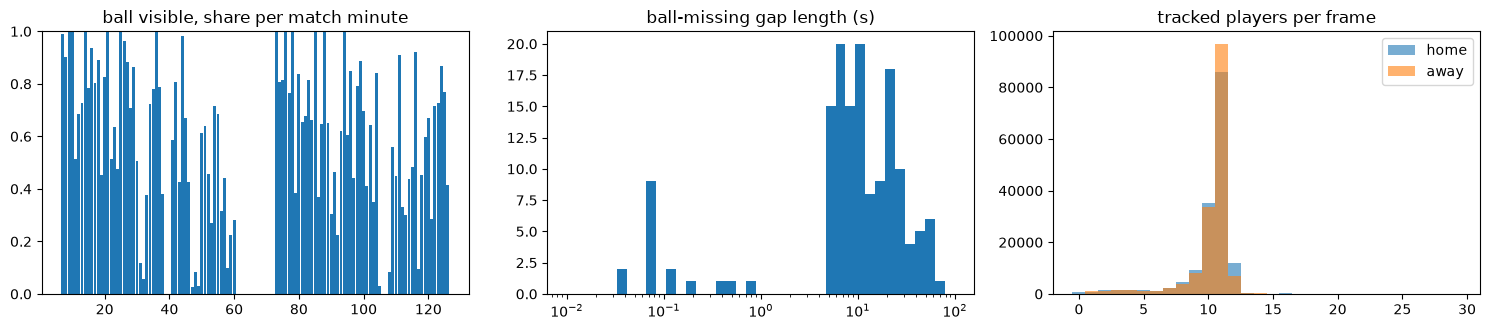

In [7]:
def run_lengths(mask):
    """(starts, lengths) of the runs of True in a boolean array."""
    m = np.concatenate(([0], mask.astype(np.int8), [0]))
    d = np.diff(m)
    s, e = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    return s, e - s

ball_obs = ~np.isnan(B[:, 0])
n_home = (~np.isnan(P[:, :, 0]))[:, slot_team == 0].sum(1)
n_away = (~np.isnan(P[:, :, 0]))[:, slot_team == 1].sum(1)
margin = CFG["pitch_margin_m"]
outside = ball_obs & ((B[:, 0] < -margin) | (B[:, 0] > L_PITCH + margin) | (B[:, 1] < -margin) | (B[:, 1] > W_PITCH + margin))

print("ball visible: all frames %.1f%% | graded frames %.1f%%" % (100 * ball_obs.mean(), 100 * ball_obs[GRADED].mean()))
print("tracked players per frame (graded): home %.1f, away %.1f" % (n_home[GRADED].mean(), n_away[GRADED].mean()))
print("ball observed OUTSIDE the pitch (+%.1f m) on %.2f%% of graded frames" % (margin, 100 * outside[GRADED].mean()))
gs, gl = run_lengths(~ball_obs & GRADED)
print("ball-missing gaps inside graded frames: %d | median %.2fs | p90 %.2fs | max %.1fs"
      % (len(gl), np.median(gl) / FPS, np.percentile(gl, 90) / FPS, gl.max() / FPS))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
minutes = np.arange(N) // (FPS * 60)
vis = pd.Series(ball_obs[GRADED]).groupby(minutes[GRADED]).mean()
ax[0].bar(vis.index, vis.values, width=0.9); ax[0].set_title("ball visible, share per match minute"); ax[0].set_ylim(0, 1)
ax[1].hist(gl / FPS, bins=np.logspace(-2, 2, 40)); ax[1].set_xscale("log"); ax[1].set_title("ball-missing gap length (s)")
ax[2].hist(n_home[GRADED], bins=np.arange(-.5, 30), alpha=.6, label="home"); ax[2].hist(n_away[GRADED], bins=np.arange(-.5, 30), alpha=.6, label="away")
ax[2].legend(); ax[2].set_title("tracked players per frame"); plt.tight_layout(); plt.show()

## Step 3 — Alignment check: reproduce the published baseline

Before building anything, prove that our loading, team mapping and frame alignment are right. The organisers' baseline (nearest tracked player to the ball + majority vote) has **published scores**. If we implement the same thing from our arrays and get the same numbers, then frames, teams and the scorer are all wired correctly.

On the **real** data, scored on the public window, expect approximately: `smooth50` spellF1 **0.3256**, `smooth125` spellF1 **0.4242** (from `EVALUATION.md`). A mismatch means a bug in loading or alignment, not a modelling problem. (In dry-run mode the numbers differ; that is expected.)

In [8]:
import baseline as bl     # starter/baseline.py: reuse the organisers' smoothing function unchanged

def nearest_team_codes(P, B, slot_team, chunk=20000):
    """Per frame: team (0 home / 1 away) of the tracked player nearest to the raw ball; -1 if no answer."""
    out = np.full(len(B), -1, np.int8)
    for a in range(0, len(B), chunk):
        sl = slice(a, a + chunk)
        d = np.hypot(P[sl, :, 0] - B[sl, None, 0], P[sl, :, 1] - B[sl, None, 1])
        d = np.where(np.isnan(d), np.inf, d)
        j = d.argmin(1)
        ok = np.isfinite(d[np.arange(len(j)), j])
        out[sl][ok] = slot_team[j[ok]]
    return out

def evaluate_labels(labels, bootstrap_n=0):
    return pm.evaluate(GT_CODES, pm.label_codes(labels), bootstrap_n=bootstrap_n)

def headline(res, title=""):
    print("%-28s spellF1 %.4f | macroF1 %.4f | alive/dead F1 %.3f | team acc (GT alive) %.3f | possessions pred %d vs GT %d | mean dur %.1fs vs %.1fs"
          % (title, res["spell_f1_mean"], res["macro_f1"], res["alive_dead_f1"], res["team_acc_gt_alive"],
             res["n_pred_spells"], res["n_gt_spells"], res["mean_spell_duration_s"], res["gt_mean_spell_duration_s"]))

near = nearest_team_codes(P, B, slot_team)
for w in (0, 25, 50, 125):
    headline(evaluate_labels(bl.smooth(near, w)), "baseline window +/-%d" % w)
print("\nREAL-data reference (public window): smooth50 spellF1 0.3256 | smooth125 spellF1 0.4242 | raw ~0.05 on the full match")

baseline window +/-0         spellF1 0.0378 | macroF1 0.5972 | alive/dead F1 0.892 | team acc (GT alive) 0.728 | possessions pred 131 vs GT 17 | mean dur 2.0s vs 14.2s
baseline window +/-25        spellF1 0.2868 | macroF1 0.6200 | alive/dead F1 0.897 | team acc (GT alive) 0.791 | possessions pred 36 vs GT 17 | mean dur 7.6s vs 14.2s
baseline window +/-50        spellF1 0.3256 | macroF1 0.6207 | alive/dead F1 0.899 | team acc (GT alive) 0.835 | possessions pred 26 vs GT 17 | mean dur 10.8s vs 14.2s
baseline window +/-125       spellF1 0.4242 | macroF1 0.5812 | alive/dead F1 0.899 | team acc (GT alive) 0.885 | possessions pred 16 vs GT 17 | mean dur 18.5s vs 14.2s

REAL-data reference (public window): smooth50 spellF1 0.3256 | smooth125 spellF1 0.4242 | raw ~0.05 on the full match


## Step 4 — Clean the ball signal

The ball is the most informative and the least reliable signal (missing on ~41% of graded frames). Three operations:

1. **Glitch removal.** An observed sample whose speed to *both* neighbouring observations exceeds `max_ball_speed` is an isolated spike: drop it.
2. **Short-gap interpolation.** Gaps up to `max_gap_s` that have an observation on both sides are linearly interpolated and flagged `2`. Longer gaps stay `NaN`: we do **not** invent ball positions over a long occlusion (the decoder will simply hold its state, which the scorer treats kindly inside a possession).
3. **Light smoothing** with a NaN-aware box filter, then velocity by finite differences.

`ball_state`: `0` missing, `1` observed, `2` interpolated.

In [9]:
def nan_box_smooth(x, w):
    if w <= 1:
        return x
    valid = ~np.isnan(x); v = np.where(valid, x, 0.0); k = np.ones(w)
    num, den = np.convolve(v, k, "same"), np.convolve(valid.astype(float), k, "same")
    out = np.where(den > 0, num / np.maximum(den, 1e-9), np.nan)
    out[~valid] = np.nan
    return out

def clean_ball(B, fps, cfg):
    """Returns ball (N,2) metres with NaN where unknown, ball_state (N,) in {0,1,2}, ball_speed (N,) m/s."""
    n = len(B); Bc = B.copy()
    # 1) isolated spikes (two passes)
    for _ in range(2):
        idx = np.flatnonzero(~np.isnan(Bc[:, 0]))
        if len(idx) < 3:
            break
        step = np.hypot(*np.diff(Bc[idx], axis=0).T) / (np.diff(idx) / fps)       # speed between consecutive observations
        spike = np.zeros(len(idx), bool)
        spike[1:-1] = (step[:-1] > cfg["max_ball_speed"]) & (step[1:] > cfg["max_ball_speed"])
        Bc[idx[spike]] = np.nan
    obs = ~np.isnan(Bc[:, 0])
    state = obs.astype(np.int8)
    # 2) interpolate short gaps that are bracketed by observations
    idx = np.flatnonzero(obs)
    if len(idx) >= 2:
        gs, gl = run_lengths(~obs)
        max_gap = int(round(cfg["max_gap_s"] * fps))
        for s, l in zip(gs, gl):
            if l <= max_gap and s > idx[0] and s + l - 1 < idx[-1]:
                sl = slice(s, s + l)
                for c in (0, 1):
                    Bc[sl, c] = np.interp(np.arange(s, s + l), idx, Bc[idx, c])
                state[sl] = 2
    # 3) smooth + velocity
    Bs = np.stack([nan_box_smooth(Bc[:, c], cfg["smooth_frames"]) for c in (0, 1)], axis=1)
    v = np.full(n, np.nan)
    ok = ~np.isnan(Bs[:, 0])
    dx, dy = np.gradient(np.where(ok, Bs[:, 0], np.nan)), np.gradient(np.where(ok, Bs[:, 1], np.nan))
    v[ok] = np.hypot(dx, dy)[ok] * fps
    return Bs, state, v

ball, ball_state, ball_speed = clean_ball(B, FPS, CFG)
print("graded frames: raw %.1f%% | after cleaning %.1f%% (observed %.1f%% + interpolated %.1f%%)"
      % (100 * ball_obs[GRADED].mean(), 100 * (ball_state[GRADED] > 0).mean(),
         100 * (ball_state[GRADED] == 1).mean(), 100 * (ball_state[GRADED] == 2).mean()))
print("ball speed (m/s) graded: median %.1f | p95 %.1f | p99 %.1f" % tuple(np.nanpercentile(ball_speed[GRADED], [50, 95, 99])))

graded frames: raw 59.3% | after cleaning 59.3% (observed 59.2% + interpolated 0.1%)
ball speed (m/s) graded: median 5.1 | p95 17.3 | p99 24.3


## Step 5 — Per-frame evidence

Everything downstream consumes a handful of per-frame signals. They are computed **once** and kept independent of the decoding weights, so you can sweep weights cheaply.

| signal | meaning |
|---|---|
| `ev` | **control evidence**: `log(control_H / control_A)` (clipped), where each team's control is `sum exp(-d^2 / 2 sigma^2)` over its tracked players, `d` = distance to the ball. Positive favours home. It is `0` when the ball is missing or **loose** (nobody within reach) — the rules say possession then stays with the last team, which is exactly what a sticky decoder does with zero evidence. |
| `ball_w` | weight of that evidence: 1 observed, `interp_weight` interpolated, 0 missing |
| `out` | ball outside the pitch rectangle (dead-ball evidence) |
| `static` | ball nearly stationary for the whole window (set-piece waiting) |
| `missing_long` | ball missing for >= `missing_min_s` (weak dead evidence) |
| `st_team` | Smart Tagging team prior in [-1, +1] (+ home). Codes whose Team tag is the *defending* side are flipped; set pieces are excluded |
| `st_sp` | inside a Smart Tagging set-piece interval |

Smart Tagging is **inferred, not truth**, and what its `Team` tag means for each code is an assumption (see `CFG["st_*"]`); Step 7 prints a diagnostic against the ground truth so you can fix the mapping.

In [10]:
def team_of_tag(text, cfg):
    t = (text or "").lower()
    if any(k in t for k in cfg["st_home_keys"]): return +1
    if any(k in t for k in cfg["st_away_keys"]): return -1
    return 0                                               # "N/A", empty, unknown

def smart_tagging_arrays(ST, n, cfg):
    st_team = np.zeros(n); st_sp = np.zeros(n)
    for r in ST.itertuples():
        a, b = max(r.start, 0), min(r.end, n)
        if b <= a:
            continue
        if r.code == "SET PIECES":
            st_sp[a:b] = 1.0
        if r.code in cfg["st_skip_codes"]:
            continue
        sign = team_of_tag(r.team, cfg)
        if r.code.startswith(tuple(cfg["st_flip_prefixes"])):
            sign = -sign
        st_team[a:b] += sign
    return np.clip(st_team, -1, 1), st_sp

def compute_features(cfg, ball, ball_state, ball_speed, chunk=20000):
    n = len(ball)
    ch, ca = np.zeros(n), np.zeros(n)
    home, away = slot_team == 0, slot_team == 1
    for a in range(0, n, chunk):                                           # chunked: N x slots matrices are big
        sl = slice(a, a + chunk)
        d = np.hypot(P[sl, :, 0] - ball[sl, None, 0], P[sl, :, 1] - ball[sl, None, 1])
        k = np.nan_to_num(np.exp(-(d ** 2) / (2 * cfg["sigma_m"] ** 2)), nan=0.0)   # NaN distance (no ball / no player) -> 0
        ch[sl], ca[sl] = k[:, home].sum(1), k[:, away].sum(1)
    eps = 1e-3
    ev = np.clip(np.log((ch + eps) / (ca + eps)), -cfg["evidence_clip"], cfg["evidence_clip"])
    ev[(ch + ca) < cfg["min_control"]] = 0.0                               # loose ball: no team evidence
    ev[ball_state == 0] = 0.0                                              # no ball: no evidence
    ball_w = np.where(ball_state == 1, 1.0, np.where(ball_state == 2, cfg["interp_weight"], 0.0))

    m = cfg["pitch_margin_m"]
    present = ball_state > 0
    out = (present & ((ball[:, 0] < -m) | (ball[:, 0] > L_PITCH + m) | (ball[:, 1] < -m) | (ball[:, 1] > W_PITCH + m))).astype(float)
    win = max(int(round(cfg["static_window_s"] * FPS)), 1)
    roll_max = pd.Series(ball_speed).rolling(win, center=True, min_periods=win // 2).max().values
    static = (present & (roll_max < cfg["static_speed"])).astype(float)
    gs, gl = run_lengths(ball_state == 0)
    missing_long = np.zeros(n)
    for s, l in zip(gs, gl):
        if l >= cfg["missing_min_s"] * FPS:
            missing_long[s:s + l] = 1.0
    st_team, st_sp = smart_tagging_arrays(ST, n, cfg)
    return dict(ev=ev, ball_w=ball_w, out=out, static=static, missing_long=missing_long,
                st_team=st_team, st_sp=st_sp, ch=ch, ca=ca)

t0 = time.time()
FEATS = compute_features(CFG, ball, ball_state, ball_speed)
print("features computed in %.0fs" % (time.time() - t0))
print(pd.DataFrame({k: pd.Series(v[GRADED]).describe()[["mean", "std", "min", "max"]] for k, v in FEATS.items()}).T.round(3))

features computed in 0s
               mean    std  min    max
ev            0.179  1.846 -4.0  4.000
ball_w        0.593  0.491  0.0  1.000
out           0.021  0.143  0.0  1.000
static        0.022  0.145  0.0  1.000
missing_long  0.406  0.491  0.0  1.000
st_team       0.186  0.839 -1.0  1.000
st_sp         0.276  0.447  0.0  1.000
ch            0.341  0.468  0.0  3.667
ca            0.299  0.466  0.0  5.463


## Step 6 — Decode with a sticky 3-state HMM (Viterbi)

A possession is an **interval**, not a sequence of independent frame votes. So instead of smoothing per-frame guesses we decode the best *path* through three states `H`, `A`, `D`:

* **Emission score per frame** (nats): `H = +ctrl`, `A = -ctrl` with `ctrl = w_ctrl * ev * ball_w + w_st_team * st_team`; `D = -dead_bias + w_out*out + w_static*static + w_setpiece*st_sp + w_missing*missing_long`.
* **Transition cost**: staying is free; `H<->A` costs `switch_cost`; entering or leaving `D` costs `dead_cost`. Raising `switch_cost` means a hand-over needs *sustained* evidence — a computational version of "controlled possession" — so brief touches and deflections do not flip the label.
* **No evidence → no change.** Occlusions and loose balls give zero evidence, so the path just continues.
* **Published facts used:** the second half is graded from frame 110,808 but kicks off at 113,742, and everything before the kickoff is `D` (FAQ); we pin those frames to `D`.
* **Post-processing:** runs shorter than `min_possession_s` / `min_dead_s` are absorbed by a neighbour.

Each half is decoded separately (the scorer treats halves separately too). Ungraded frames get `X`.

In [11]:
LETTER = np.array(["H", "A", "D"])

def build_scores(F, cfg):
    ctrl = cfg["w_ctrl"] * F["ev"] * F["ball_w"] + cfg["w_st_team"] * F["st_team"]
    dead = (-cfg["dead_bias"] + cfg["w_out"] * F["out"] + cfg["w_static"] * F["static"]
            + cfg["w_setpiece"] * F["st_sp"] + cfg["w_missing"] * F["missing_long"])
    return np.stack([ctrl, -ctrl, dead], axis=1)

def viterbi(scores, switch_cost, dead_cost):
    """Best state path for (T,3) per-frame scores (higher = better) with H/A/D transition penalties."""
    T = len(scores)
    trans = np.array([[0, -switch_cost, -dead_cost],
                      [-switch_cost, 0, -dead_cost],
                      [-dead_cost, -dead_cost, 0]], dtype=float)
    delta = np.empty((T, 3)); psi = np.empty((T, 3), np.int8)
    delta[0] = scores[0]
    for t in range(1, T):
        cand = delta[t - 1][:, None] + trans            # (previous state, current state)
        psi[t] = cand.argmax(0)
        delta[t] = cand.max(0) + scores[t]
    path = np.empty(T, np.int8); path[-1] = delta[-1].argmax()
    for t in range(T - 1, 0, -1):
        path[t - 1] = psi[t, path[t]]
    return path

def enforce_min_duration(path, min_alive, min_dead):
    """Repeatedly absorb the shortest too-short run into the longer neighbour (or the common one)."""
    path = path.copy()
    for _ in range(100000):
        change = np.flatnonzero(np.diff(path) != 0) + 1
        starts, ends = np.r_[0, change], np.r_[change, len(path)]
        lens, states = ends - starts, path[starts]
        if len(states) == 1:
            break
        bad = np.flatnonzero(lens < np.where(states == 2, min_dead, min_alive))
        if not len(bad):
            break
        k = bad[np.argmin(lens[bad])]
        if k == 0:
            new = states[1]
        elif k == len(states) - 1:
            new = states[k - 1]
        elif states[k - 1] == states[k + 1]:
            new = states[k - 1]
        else:
            new = states[k - 1] if lens[k - 1] >= lens[k + 1] else states[k + 1]
        path[starts[k]:ends[k]] = new
    return path

def decode_match(F, cfg):
    """Full-length label array ('H','A','D', and 'X' on ungraded frames) + per-half raw/final paths."""
    scores = build_scores(F, cfg)
    labels = np.full(N, "X", dtype="<U1"); paths = {}
    for half, a, b in HALVES:
        sc = scores[a:b + 1].copy()
        kick = MATCH["pre_kickoff_dead"].get(half)
        if kick:                                           # graded but before kickoff: all dead ball
            sc[:kick - a, :2] = -1e3
        raw = viterbi(sc, cfg["switch_cost"], cfg["dead_cost"])
        final = enforce_min_duration(raw, int(round(cfg["min_possession_s"] * FPS)), int(round(cfg["min_dead_s"] * FPS)))
        labels[a:b + 1] = LETTER[final]
        paths[half] = (raw, final)
    return labels, paths

t0 = time.time()
labels, paths = decode_match(FEATS, CFG)
print("decoded in %.1fs | label counts on graded frames:" % (time.time() - t0),
      {l: int(((labels == l) & GRADED).sum()) for l in "HAD"})

decoded in 1.0s | label counts on graded frames: {'H': 74525, 'A': 49371, 'D': 34961}


## Step 7 — Score, validate, inspect

`evaluate_labels` calls the **official scorer** (`possession_metrics.evaluate`) on whatever ground truth is loaded (public 5 minutes in real mode). Read the possession counts first: a pipeline that scores well per frame but invents hundreds of possessions will rank badly on spellF1.

Reminder: with 17 possessions, differences of a few spellF1 points are noise. Use `bootstrap_n=1000` to see the interval.

In [12]:
res = evaluate_labels(labels, bootstrap_n=0)
headline(res, "this pipeline")
headline(evaluate_labels(bl.smooth(near, 50)), "baseline window +/-50")
print()
print("confusion (rows = GT H/A/D/X, cols = pred H/A/D/X):")
print(pd.DataFrame(res["confusion"], index=list("HADX"), columns=list("HADX")))
print("\nper-class F1:", {k: round(v["f1"], 3) for k, v in res["per_class"].items()})
print("spellF1 by IoU threshold:", {k: round(v["f1"], 3) for k, v in res["spell_f1"].items()})
tr = res["transitions"]
print("transition F1 @tau:", {k: round(v["f1"], 3) for k, v in tr.items()})

this pipeline                spellF1 0.4000 | macroF1 0.6210 | alive/dead F1 0.903 | team acc (GT alive) 0.793 | possessions pred 8 vs GT 17 | mean dur 34.5s vs 14.2s
baseline window +/-50        spellF1 0.3256 | macroF1 0.6207 | alive/dead F1 0.899 | team acc (GT alive) 0.835 | possessions pred 26 vs GT 17 | mean dur 10.8s vs 14.2s

confusion (rows = GT H/A/D/X, cols = pred H/A/D/X):
       H      A      D      X
H   2799    655      0      0
A    406   1982    189      0
D    795    273    401      0
X  70525  46461  34371  40462

per-class F1: {'H': 0.751, 'A': 0.722, 'D': 0.39}
spellF1 by IoU threshold: {0.3: 0.48, 0.4: 0.48, 0.5: 0.48, 0.6: 0.32, 0.7: 0.24}
transition F1 @tau: {12: 0.071, 25: 0.071}


In [13]:
# Optional: honest uncertainty. Slow-ish; use 200 while iterating, 1000 for a final look.
res_b = evaluate_labels(labels, bootstrap_n=200)
print("spellF1 %.3f  (5-95%% bootstrap interval %.3f - %.3f)" % (res_b["spell_f1_mean"], res_b["spell_bootstrap_low"], res_b["spell_bootstrap_high"]))

spellF1 0.400  (5-95% bootstrap interval 0.192 - 0.607)


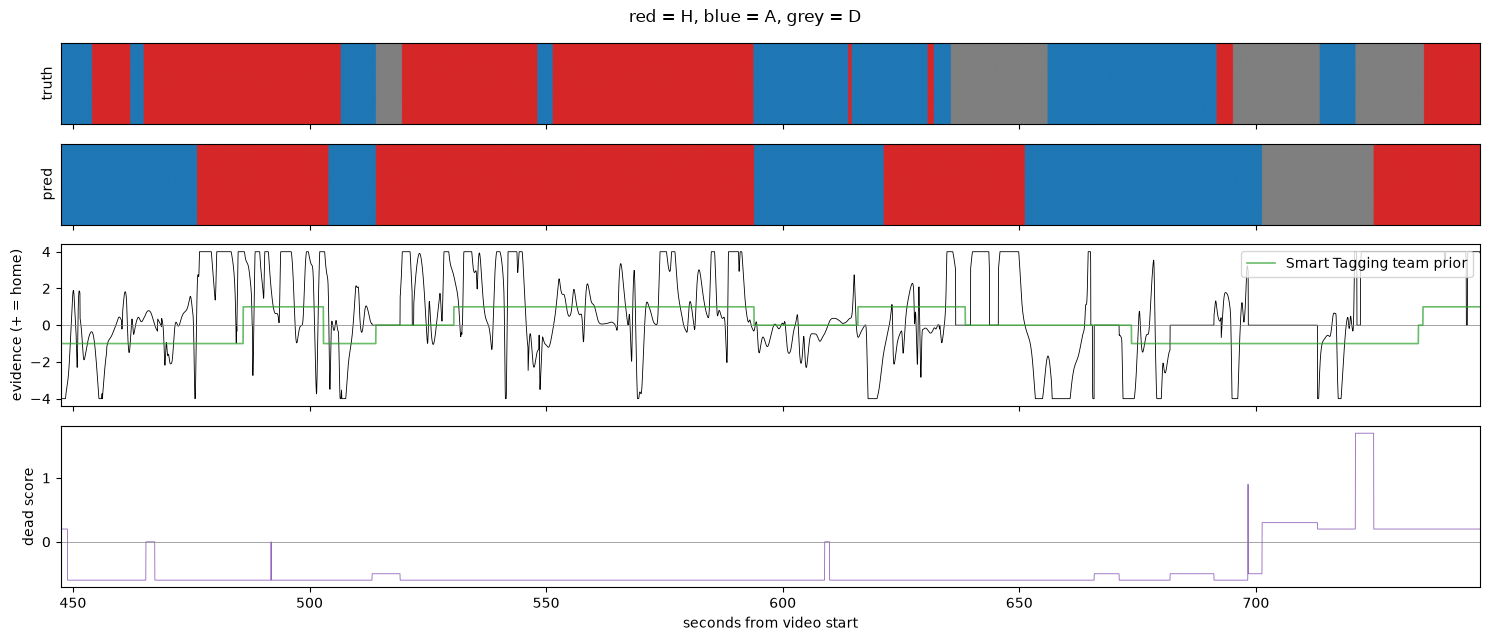

In [14]:
# Timeline: ground truth vs prediction over the first labelled stretch, with the evidence underneath.
runs = pm.valid_runs(GT_CODES)
w0 = runs[0][0]; w1 = min(runs[0][1], w0 + 7500)
x = np.arange(w0, w1) / FPS
cmap = plt.matplotlib.colors.ListedColormap(["#d62728", "#1f77b4", "#7f7f7f", "#ffffff"])   # H red, A blue, D grey, X white
fig, ax = plt.subplots(4, 1, figsize=(15, 6.5), sharex=True, gridspec_kw=dict(height_ratios=[1, 1, 2, 2]))
ax[0].imshow(GT_CODES[w0:w1][None, :], aspect="auto", cmap=cmap, vmin=0, vmax=3, extent=[x[0], x[-1], 0, 1]); ax[0].set_ylabel("truth"); ax[0].set_yticks([])
pred_codes = pm.label_codes(labels)
ax[1].imshow(pred_codes[w0:w1][None, :], aspect="auto", cmap=cmap, vmin=0, vmax=3, extent=[x[0], x[-1], 0, 1]); ax[1].set_ylabel("pred"); ax[1].set_yticks([])
ax[2].plot(x, FEATS["ev"][w0:w1] * FEATS["ball_w"][w0:w1], lw=.6, color="k"); ax[2].axhline(0, color="grey", lw=.5)
ax[2].plot(x, FEATS["st_team"][w0:w1], lw=1.2, color="tab:green", alpha=.7, label="Smart Tagging team prior")
ax[2].set_ylabel("evidence (+ = home)"); ax[2].legend(loc="upper right")
ax[3].plot(x, build_scores(FEATS, CFG)[w0:w1, 2], lw=.6, color="tab:purple"); ax[3].axhline(0, color="grey", lw=.5); ax[3].set_ylabel("dead score"); ax[3].set_xlabel("seconds from video start")
plt.suptitle("red = H, blue = A, grey = D"); plt.tight_layout(); plt.show()

In [15]:
# Diagnostic 1: does the Smart Tagging team tag point at the team the ground truth says is in possession?
# Only rows that overlap labelled frames can be checked (real mode: the 5 public minutes, so treat as a rough
# sign-convention check, not a statistic). If a code agrees far less than 50%, flip it in CFG["st_flip_prefixes"].
rows = []
for r in ST.itertuples():
    a, b = max(r.start, 0), min(r.end, N)
    g = GT_CODES[a:b]
    if b <= a or (g == pm.X).all() or r.code in CFG["st_skip_codes"]:
        continue
    sign = team_of_tag(r.team, CFG) * (-1 if r.code.startswith(tuple(CFG["st_flip_prefixes"])) else 1)
    h, aw = int((g == pm.H).sum()), int((g == pm.A).sum())
    if sign != 0 and h + aw > 0:
        rows.append(dict(code=r.code, team_tag=r.team, sign=sign, gt_home=h, gt_away=aw, agrees=(sign * (h - aw) > 0)))
diag = pd.DataFrame(rows)
if len(diag):
    print(diag.groupby("code")["agrees"].agg(["count", "mean"]).rename(columns={"mean": "agree_rate"}).round(2))
else:
    print("no labelled Smart Tagging rows with a usable team tag to check")

# Diagnostic 2: do set-piece intervals coincide with dead-ball frames in the ground truth?
sp = ST[ST["code"] == "SET PIECES"]
rows = []
for r in sp.itertuples():
    g = GT_CODES[max(r.start, 0):min(r.end, N)]
    lab = g[g != pm.X]
    if len(lab):
        rows.append(dict(type=r.type, frames=len(lab), share_dead=float((lab == pm.D).mean())))
print("\nset-piece intervals overlapping labelled frames:", len(rows))
if rows:
    print(pd.DataFrame(rows).round(2).to_string(index=False))

                              count  agree_rate
code                                           
ATTACKING TRANSITION              1        1.00
BALL IN FINAL THIRD               4        0.75
BALL IN THE BOX                   3        0.67
BUILD UP                          1        1.00
CREATING CHANCES                  1        1.00
DEFENDING IN ATTACKING THIRD      1        1.00
DEFENDING IN DEFENSIVE THIRD      1        1.00
DEFENDING IN MIDDLE THIRD         5        0.80
DEFENSIVE TRANSITION              1        1.00
LONG BALL                         1        1.00
PLAYERS IN THE BOX                3        0.33
PROGRESSION                       5        0.80

set-piece intervals overlapping labelled frames: 3
            type  frames  share_dead
Kick Off (Start)      37        0.00
       Goal Kick     365        0.19
       Free Kick     875        0.76


In [16]:
# Diagnostic 3: what do the possessions in the labelled window look like, and what did we predict there?
def spell_table(codes, a, b):
    out, start = [], a
    for t in range(a + 1, b + 1):
        if t == b or codes[t] != codes[start]:
            out.append((start, t, "HADX"[codes[start]], (t - start) / FPS)); start = t
    return pd.DataFrame(out, columns=["start", "end", "label", "seconds"])
a, b = runs[0]; b = min(b, a + 7500)
cmp_ = pd.concat({"truth": spell_table(GT_CODES, a, b), "pred": spell_table(pred_codes, a, b)}, axis=1)
print("segments in window: truth %d, pred %d" % (cmp_["truth"]["start"].notna().sum(), cmp_["pred"]["start"].notna().sum()))
cmp_.round(1).head(30)

segments in window: truth 21, pred 9


truth                          pred                       
    start    end label seconds    start      end label seconds
0   11185  11351     A     6.6  11185.0  11906.0     A    28.8
1   11351  11553     H     8.1  11906.0  12600.0     H    27.8
2   11553  11624     A     2.8  12600.0  12851.0     A    10.0
3   11624  12665     H    41.6  12851.0  14849.0     H    79.9
4   12665  12851     A     7.4  14849.0  15534.0     A    27.4
5   12851  12989     D     5.5  15534.0  16280.0     H    29.8
6   12989  13704     H    28.6  16280.0  17533.0     A    50.1
7   13704  13785     A     3.2  17533.0  18123.0     D    23.6
8   13785  14846     H    42.4  18123.0  18685.0     H    22.5
9   14846  15346     A    20.0      NaN      NaN   NaN     NaN
10  15346  15365     H     0.8      NaN      NaN   NaN     NaN
11  15365  15766     A    16.0      NaN      NaN   NaN     NaN
12  15766  15799     H     1.3      NaN      NaN   NaN     NaN
13  15799  15889     A     3.6      NaN      NaN   NaN     NaN
14  15889  16400     D    20.4      NaN      NaN   NaN     NaN
15  16400  17293     A    35.7      NaN      NaN   NaN     NaN
16  17293  17380     H     3.5      NaN      NaN   NaN     NaN
17  17380  17838     D    18.3      NaN      NaN   NaN     NaN
18  17838  18027     A     7.6      NaN      NaN   NaN     NaN
19  18027  18389     D    14.5      NaN      NaN   NaN     NaN
20  18389  18685     H    11.8      NaN      NaN   NaN     NaN

## Step 8 — Parameter sanity sweep (by structure, not by public score)

The spellF1 ranking punishes the *number* and *length* of possessions. A good first calibration needs no labels at all: pick decoding parameters that give a **plausible possession count and duration**.

Real-match reference (from the 5 public minutes, so rough): ~3.4 possessions per minute, mean ~14 s, home share ~57%, over ~106 graded minutes, i.e. **a few hundred possessions per match**. The expected count is printed below.

`SHOW_PUBLIC_SCORE` adds the public spellF1 as a column for curiosity only. Leave it off when choosing: the organisers demonstrated that the public window selects the wrong value even for a one-parameter baseline.

In [17]:
SHOW_PUBLIC_SCORE = False
RUNS_ALL = [(a, b + 1) for _, a, b in HALVES]
graded_min = GRADED.sum() / FPS / 60
lab_runs = pm.valid_runs(GT_CODES)
lab_min = sum(e - s for s, e in lab_runs) / FPS / 60
gt_rate = pm.possession_stats(GT_CODES, lab_runs)["n_spells"] / lab_min if lab_min else float("nan")
print("reference rate %.2f possessions/min over %.1f labelled min -> expect roughly %.0f possessions in %.0f graded min"
      % (gt_rate, lab_min, gt_rate * graded_min, graded_min))

def sweep(param, values, base=CFG, feats=None):
    rows = []
    for v in values:
        lab, _ = decode_match(feats or FEATS, dict(base, **{param: v}))
        st = pm.possession_stats(pm.label_codes(lab), RUNS_ALL)
        row = {param: v, "possessions": st["n_spells"], "per_min": round(st["n_spells"] / graded_min, 2),
               "mean_dur_s": round(st["mean_duration_s"], 1), "home_share": round(st["home_share"], 2),
               "dead_share": round(float(((lab == "D") & GRADED).sum() / GRADED.sum()), 2)}
        if SHOW_PUBLIC_SCORE:
            row["public_spellF1"] = round(evaluate_labels(lab)["spell_f1_mean"], 3)
        rows.append(row)
    return pd.DataFrame(rows)

sweep("switch_cost", [5, 10, 15, 20, 30, 45, 70])

reference rate 3.40 possessions/min over 5.0 labelled min -> expect roughly 360 possessions in 106 graded min


,switch_cost,possessions,per_min,mean_dur_s,home_share,dead_share
0,5,242,2.29,20.6,0.61,0.22
1,10,171,1.61,29.0,0.61,0.22
2,15,149,1.41,33.3,0.60,0.22
3,20,140,1.32,35.4,0.60,0.22
4,30,138,1.30,35.9,0.58,0.22
5,45,138,1.30,35.9,0.58,0.22
6,70,138,1.30,35.9,0.58,0.22


In [18]:
sweep("dead_cost", [3, 6, 10, 15, 25])

,dead_cost,possessions,per_min,mean_dur_s,home_share,dead_share
0,3,258,2.44,19.4,0.60,0.21
1,6,179,1.69,27.7,0.59,0.22
2,10,149,1.41,33.3,0.60,0.22
3,15,137,1.29,36.0,0.61,0.22
4,25,130,1.23,38.1,0.61,0.22


In [19]:
sweep("w_ctrl", [0.05, 0.1, 0.2, 0.4])

,w_ctrl,possessions,per_min,mean_dur_s,home_share,dead_share
0,0.05,110,1.04,43.1,0.6,0.25
1,0.10,149,1.41,33.3,0.6,0.22
2,0.20,257,2.43,20.3,0.6,0.18
3,0.40,378,3.57,14.2,0.6,0.16


## Step 9 — Export and reproducibility

Writes the submission CSV (`frame,label`, exactly `N` rows), runs the **official validator checks**, and stores the configuration and a checksum so the same file can be regenerated. Real-mode output goes to `evaluation/results/<TEAM_NAME>.csv` (that folder is git-ignored and is what `run_evaluation.py` scores); dry-run output stays in `cache/`.

Before submitting, also run from a terminal: `python evaluation/validate_submission.py evaluation/results/<TEAM_NAME>.csv` and `python evaluation/run_evaluation.py`.

In [20]:
def write_submission(labels, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"frame": np.arange(len(labels)), "label": labels}).to_csv(path, index=False)
    return path

out_path = (ROOT / "cache" / "synthetic" / (TEAM_NAME + "_synthetic.csv")) if SYNTHETIC \
    else (ROOT / "evaluation" / "results" / (TEAM_NAME + ".csv"))
write_submission(labels, out_path)

table = pm.read_label_csv(out_path)
problem = pm.validate_submission(table, N)
print("validation:", "OK" if problem is None else "FAILED -> " + problem)
print("rows:", len(table), "| labels:", table["label"].value_counts().to_dict())

md5 = hashlib.md5(Path(out_path).read_bytes()).hexdigest()
runs_dir = ROOT / "runs"; runs_dir.mkdir(exist_ok=True)
record = dict(team=TEAM_NAME, mode="synthetic" if SYNTHETIC else "real", written=time.strftime("%Y-%m-%d %H:%M:%S"),
              csv=str(out_path.relative_to(ROOT)), md5=md5, numpy=np.__version__, pandas=pd.__version__, config=CFG)
cfg_path = runs_dir / (TEAM_NAME + ("_synthetic" if SYNTHETIC else "") + "_config.json")
cfg_path.write_text(json.dumps(record, indent=1, default=list))
print("config + checksum saved:", cfg_path.relative_to(ROOT), "| md5", md5)

# Keep derived match data out of git (the terms forbid publishing it).
gi = ROOT / ".gitignore"
text = gi.read_text() if gi.exists() else ""
missing = [e for e in ("cache/", "data/") if e not in text]
if missing:
    gi.write_text(text + "\n# derived / gated match data - never commit\n" + "\n".join(missing) + "\n")
    print("added to .gitignore:", missing)

validation: OK
rows: 199319 | labels: {'H': 74525, 'A': 49371, 'X': 40462, 'D': 34961}
config + checksum saved: runs/my_team_config.json | md5 9daa2c90824ea4f806ff83fa77b648ab


## What to improve next (in rough order of expected payoff)

1. **Learn the emission model** instead of hand-set weights: fit a small GBM / logistic model on the 5 public minutes *only to check direction*, or better, use weak supervision (Smart Tagging team tags + restarts) on the whole match; keep it simple and regularised, 17 possessions cannot support much tuning.
2. **Restarts as anchors.** Every dead-ball stretch ends with a restart by a known team; use set-piece tags (type, side, team) plus where the ball sits to decide *who restarts*, which fixes the label right after each `D`.
3. **Better "controlled possession" evidence:** touches inferred from ball acceleration changes near a player, pass chains (same team nearest on consecutive touches), and ball height (a 2D position of an airborne ball is misleading).
4. **Dead-ball detector.** Player formation freezes, players gathering around a throw-in/corner spot, ball outside the lines (check the Step 2 out-of-pitch share first), and homography-based pitch zones (corner arcs, goal areas).
5. **Duration model:** replace the minimum-duration clean-up with a proper HSMM; use different minimums for `D` and for alive possessions.
6. **Second view:** the broadcast tracking can fill ball gaps, but it is not frame-aligned and needs a mapping you must build.
7. **Failure analysis loop:** list the largest disagreements with the public GT (Step 7, Diagnostic 3), watch those moments in the video, and turn each pattern into a feature, never into a hand-edited label (hand labelling is disqualifying).

### Deliverables checklist
* `<team>.csv` — 199,319 rows, validated.
* Public repo: this notebook (also `jupyter nbconvert --to script`), pinned `requirements.txt`, run instructions, **no match data** (`data/` and `cache/` ignored). Rerunning must reproduce the same file.
* Technical document (`<team>.pdf` or `.md`): approach and why; which assets were used and which were tried and dropped; the possession rules you implemented (loose balls, challenges, restarts); limitations; how to reproduce.